# Histórico publicado 2015–2025, clima ERA5 y HGB

Este notebook documenta la integración que alimenta el mapa y Haz tus predicciones.
PM2.5 y PM10 proceden de exportaciones horarias públicas de **SISAIRE / SDA Bogotá**;
las lecturas válidas de las muestras RMCAB anteriores tienen prioridad en los solapamientos.
ERA5 se conserva como **reanálisis meteorológico**, separado de las mediciones.

Fuentes: [SISAIRE](https://sisaire.ideam.gov.co/ideam-sisaire-web/consultas.xhtml),
[RMCAB](https://www.ambientebogota.gov.co/es/red-de-monitoreo-de-calidad-del-aire-de-bogota-rmcab),
[Open-Meteo / ERA5](https://open-meteo.com/en/docs/historical-weather-api).

Los intervalos SISAIRE pueden terminar en el siguiente minuto 00 o en minuto 59.
Se usa el final de la hora (`inicio + 1 h`) y la fecha de reporte es `datetime - 1 h`.
Los intervalos desalineados y duplicados contradictorios se excluyen; los duplicados
idénticos se conservan una sola vez. Los originales descargados y sus hashes quedan
en la caché. No se certifica la validación final de cada sensor ni sus reubicaciones históricas.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'data/history/observations_manifest.json').exists()
# El kernel se ejecuta desde la raíz del repositorio.
from dash2.history_data import load_observations
from dash2.weather_data import load_weather
raw = load_observations(ROOT)
meta = json.loads((ROOT/'data/history/observations_manifest.json').read_text(encoding='utf-8'))
print(f"{len(raw):,} registros de estación/hora; {raw.report_date.nunique():,} días; {raw.station_id.nunique()} estaciones referenciadas")
pd.read_csv(ROOT/'data/history/coverage_by_year.csv')

1,323,391 registros de estación/hora; 4,013 días; 19 estaciones referenciadas


,year,report_days,calendar_days,sampled_calendar_pct,listed_stations,station_hours,pm_25_observed,pm_10_observed,temperature_observed,humidity_observed
0,2015,365,365,100.00,12,94923,79108,92727,168,144
1,2016,366,366,100.00,13,90855,75039,87506,168,144
2,2017,365,365,100.00,13,91733,84424,87081,168,168
3,2018,365,365,100.00,13,92609,86747,88812,168,168
4,2019,365,365,100.00,14,101925,92777,98690,216,192
5,2020,361,366,98.63,17,108796,105393,99885,216,192
6,2021,365,365,100.00,19,145936,138113,137014,310,206
7,2022,365,365,100.00,19,144205,139554,133200,336,216
8,2023,365,365,100.00,19,143524,139346,135835,311,238
9,2024,366,366,100.00,19,153741,146395,149459,312,240


In [2]:
sources = pd.DataFrame(meta['sources'])
exports = sources.loc[sources.kind.eq('SISAIRE_hourly_export')]
columns = ['start','end','variable','rows','source_days','excluded_unaligned_intervals','identical_duplicates_removed','conflicting_duplicate_rows_excluded']
display(exports.reindex(columns=columns).fillna(0))
display(pd.DataFrame(meta['overlap']))
print('Estaciones sin correspondencia segura excluidas:', meta['excluded_unmapped_station_rows'])
assert not raw.duplicated(['station_id','datetime']).any()
assert not any(raw[f'{v}_origin'].isin(['imputed','simulated','weather_reanalysis']).any() for v in ['pm_25','pm_10'])

,start,end,variable,rows,source_days,excluded_unaligned_intervals,identical_duplicates_removed,conflicting_duplicate_rows_excluded
0,2015-01-01,2015-12-31,PM10,92727.0,365.0,0.0,0.0,0.0
1,2015-01-01,2015-12-31,PM2.5,79106.0,365.0,0.0,0.0,0.0
2,2016-01-01,2016-12-31,PM10,87482.0,366.0,0.0,0.0,0.0
3,2016-01-01,2016-12-31,PM2.5,75015.0,366.0,0.0,0.0,0.0
4,2017-01-01,2017-12-31,PM10,87054.0,365.0,0.0,0.0,0.0
5,2017-01-01,2017-12-31,PM2.5,84393.0,365.0,0.0,0.0,0.0
6,2018-01-01,2018-12-31,PM10,88789.0,365.0,0.0,0.0,0.0
7,2018-01-01,2018-12-31,PM2.5,86723.0,365.0,0.0,0.0,0.0
8,2019-01-01,2019-12-31,PM10,107357.0,365.0,0.0,0.0,0.0
9,2019-01-01,2019-12-31,PM2.5,101302.0,365.0,0.0,0.0,0.0


,variable,overlap_rows,different_rows,priority
0,pm_25,31989,9354,RMCAB existing valid readings preserved; other...
1,pm_10,33553,11770,RMCAB existing valid readings preserved; other...
2,temperature,0,0,RMCAB existing valid readings preserved; other...
3,humidity,0,0,RMCAB existing valid readings preserved; other...


Estaciones sin correspondencia segura excluidas: {'P_CAMI - FONTIBÓN': 115609, 'BOSA': 13256}


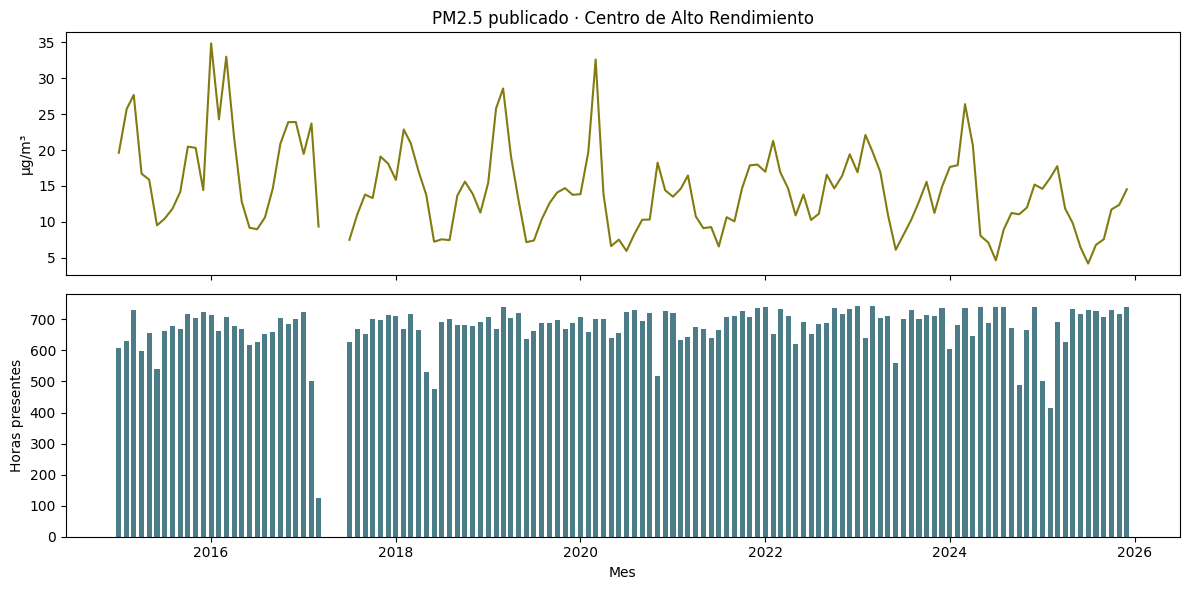

In [3]:
station = raw.loc[raw.station_id.eq('5')].set_index('datetime')
monthly = station.pm_25.resample('MS').mean()
counts = station.pm_25.resample('MS').count()
fig, axes = plt.subplots(2, 1, figsize=(12,6), sharex=True)
axes[0].plot(monthly.index, monthly.values, color='#827b10')
axes[0].set(title='PM2.5 publicado · Centro de Alto Rendimiento', ylabel='µg/m³')
axes[1].bar(counts.index, counts.values, width=20, color='#4d7c89')
axes[1].set(ylabel='Horas presentes', xlabel='Mes')
fig.tight_layout(); plt.show()
# Un promedio mensual se calcula con las horas presentes; no prueba cobertura completa.

weather_reanalysis 385728 registros; celdas: 4


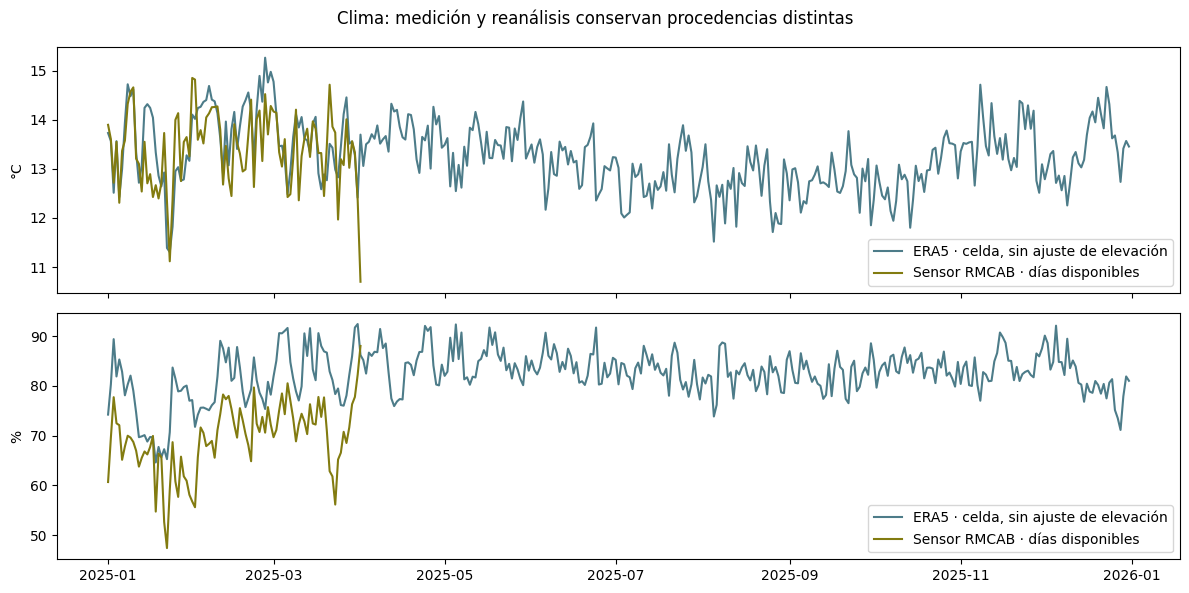

Weather data by Open-Meteo.com; ERA5 by ECMWF / Copernicus Climate Change Service.


In [4]:
weather, mapping, wm = load_weather(ROOT)
print(wm['record_type'], wm['rows'], 'registros; celdas:', len(wm['grid_cells']))
assert wm['hours_per_grid'] == 4018 * 24
grid = mapping.loc[mapping.station_id.eq('5'),'grid_id'].iloc[0]
context = weather.loc[weather.grid_id.eq(grid)].set_index('datetime').loc['2025']
fig, axes = plt.subplots(2,1,figsize=(12,6),sharex=True)
for ax, var, unit in zip(axes,['temperature','humidity'],['°C','%']):
    ax.plot(context[var].resample('D').mean(),label='ERA5 · celda, sin ajuste de elevación',color='#4d7c89')
    measured = station[var].loc['2025'].resample('D').mean()
    ax.plot(measured,label='Sensor RMCAB · días disponibles',color='#827b10')
    ax.set_ylabel(unit);ax.legend()
fig.suptitle('Clima: medición y reanálisis conservan procedencias distintas');fig.tight_layout();plt.show()
# La malla ERA5 es 0,25°: no resuelve el clima de cada barrio.
print(wm['attribution'])

## Modelo y evaluación

Se mantiene **HistGradientBoostingRegressor**, con los parámetros fijos del experimento anterior.
El desarrollo usa entrenamiento 2015–2023 y cuatro semanas de 2024. El ajuste final
usa 2015–2024 y se evalúa exclusivamente en las semanas 15–21 de enero, abril,
julio y octubre de 2025. Se purgan etiquetas que alcanzan el corte.

Cada modelo predice un punto a 24, 48 o 72 h. Los objetivos, el PM del origen y sus
rezagos proceden de mediciones; nunca del KNN del mapa ni de valores sintéticos.
ERA5 aporta predictores meteorológicos en el origen, sin usar clima futuro.
Es un experimento retrospectivo: las revisiones y demoras de ERA5 y de los sensores
impiden asumir disponibilidad operativa exacta al emitir un pronóstico.
La evaluación es sobre estaciones conocidas, no una validación espacial por barrios.

In [5]:
report = ROOT/'data/reports/hgb_2015_2025'
experiment = json.loads((report/'experiment.json').read_text(encoding='utf-8'))
print(experiment['training_scope'])
for phase in ['development','holdout']:
    folds = pd.read_csv(report/f'{phase}_folds.csv')
    assert (pd.to_datetime(folds.train_target_max, utc=True) < pd.to_datetime(folds.validation_origin_start, utc=True)).all()
    print(phase)
    display(pd.read_csv(report/f'{phase}_scores.csv'))
assert experiment['synthetic_targets_used'] is False
assert experiment['maps_used_for_training'] is False
assert experiment['future_weather_used'] is False
for relative, expected in experiment['input_sha256'].items():
    assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest() == expected
package = json.loads((ROOT/'data/forecasts/hgb_historical.json').read_text(encoding='utf-8'))
assert hashlib.sha256((ROOT/'data/forecasts/hgb_historical.csv.gz').read_bytes()).hexdigest() == package['forecast_sha256']
print('Integridad y cortes temporales verificados. No se publican intervalos de incertidumbre calibrados.')

Mediciones publicadas de 2015–2024; prueba final en cuatro semanas de 2025
development


,target,horizon_hours,method,n,MAE_ug_m3,RMSE_ug_m3,baseline_MAE,MAE_skill_vs_persistence
0,pm_10,24,hgb_native_missing,11259,12.211211,16.121114,13.751195,0.111989
1,pm_10,24,persistence,11259,13.751195,20.050834,13.751195,0.000000
2,pm_10,48,hgb_native_missing,11227,13.590182,17.390356,14.614358,0.070080
3,pm_10,48,persistence,11227,14.614358,21.050625,14.614358,0.000000
4,pm_10,72,hgb_native_missing,11172,15.019766,18.898734,17.420247,0.137798
5,pm_10,72,persistence,11172,17.420247,24.910472,17.420247,0.000000
6,pm_25,24,hgb_native_missing,10942,6.671291,8.952319,7.124840,0.063657
7,pm_25,24,persistence,10942,7.124840,10.855610,7.124840,0.000000
8,pm_25,48,hgb_native_missing,10761,7.465811,9.627053,7.373060,-0.012580
9,pm_25,48,persistence,10761,7.373060,11.025296,7.373060,0.000000


holdout


,target,horizon_hours,method,n,MAE_ug_m3,RMSE_ug_m3,baseline_MAE,MAE_skill_vs_persistence
0,pm_10,24,hgb_native_missing,9692,13.272358,18.236265,15.738826,0.156712
1,pm_10,24,persistence,9692,15.738826,23.318765,15.738826,0.000000
2,pm_10,48,hgb_native_missing,9640,14.177183,19.139319,16.633921,0.147694
3,pm_10,48,persistence,9640,16.633921,24.438219,16.633921,0.000000
4,pm_10,72,hgb_native_missing,9620,14.498331,19.219606,19.150936,0.242944
5,pm_10,72,persistence,9620,19.150936,27.345331,19.150936,0.000000
6,pm_25,24,hgb_native_missing,9692,6.088668,8.014276,6.778652,0.101788
7,pm_25,24,persistence,9692,6.778652,9.844678,6.778652,0.000000
8,pm_25,48,hgb_native_missing,9654,6.550986,8.433701,7.380495,0.112392
9,pm_25,48,persistence,9654,7.380495,10.609207,7.380495,0.000000


Integridad y cortes temporales verificados. No se publican intervalos de incertidumbre calibrados.


## Aplicación y reproducción

El mapa conserva los 1.160 sectores y sus dos opciones. **Datos originales** usa
únicamente fechas con mediciones; **Datos con tratamiento** preserva esas fuentes,
completa clima con ERA5 y mantiene el relleno exploratorio de PM donde falte soporte.
ERA5 no recibe ruido sintético. El hover y los CSV distinguen los orígenes.
Predicciones permite la misma elección para el histórico meteorológico; cambiarla
no cambia las etiquetas ni la evaluación del modelo.

Desde la raíz, con `requirements-research.txt` instalado:

```bash
python -B -m research.collect_sisaire --network
python -B -m research.weather_history --network
python -B -m research.build_observed_history
python -B -m research.train_history
python -B -m research.publish_predictions
python -B -m research.neighborhood_history
```

La red se usa solo con `--network`. Las exportaciones se reutilizan desde caché,
con SHA256 y parámetros de consulta. Los CSV de muestras originales permanecen intactos.
Los modelos no se entrenan al hacer clic en la web. La interfaz sirve resultados
históricos precalculados y verifica sus hashes. Tras reconstruir, reiniciar Django.
La amplitud aleatoria de los rellenos de PM no representa información nueva ni incertidumbre calibrada.